# Chapter 3: Comprehensive Exploratory Data Analysis, Geospatial Mapping & Bivariate Relationships

**Course:** IT 462 - Exploratory Data Analysis  
**Institution:** Dhirubhai Ambani Institute of Information and Communication Technology (DA-IICT)  
**Mentor:** Dr. Gopinath Panda  
**Topic:** How Data Centers & AI Supercomputers Affect the Environment and Grid Infrastructure  

---

## 3.1 Executive Summary & Chapter Scope
Following the rigorous data ingestion (Chapter 1) and multi-stage physics-informed imputation and cleaning pipeline (Chapter 2), we possess a validated, $100\%$ complete production dataset (`cleaned_datacenter_environmental_dataset.csv`) comprising **1,733 US data centers** across **74 operational, geospatial, and environmental attributes**.

**Objectives of Chapter 3:**
1. **Univariate Distribution Diagnostics:** Profile the statistical shape of critical continuous features (Capacity, Energy Demand, Carbon Emissions, Grid Intensity) using Kernel Density Estimation (KDE) and Quantile-Quantile (QQ) normal probability plots.
2. **Categorical & Market Landscape:** Analyze industry concentration across hyperscale cloud titans, colocation providers, cooling technologies, and operational development pipelines.
3. **Geospatial & Spatial Cluster Analysis:** Map the geographic distribution of data center clusters across the continental United States, identifying the primary hyperscale corridors (Northern Virginia, Silicon Valley, Texas, Phoenix, Chicago, Atlanta) and evaluating their colocation with carbon-intensive electrical grids.
4. **Bivariate & Multivariate Relationships:** Conduct Pearson and Spearman correlation analyses, inspect high-correlation bivariate relationships, and compute **Cramér's V** association matrices for multi-class categorical features.
5. **Synthesis for Predictive Modeling:** Provide formal statistical insights to guide feature engineering and predictive modeling in Chapter 4.


In [1]:
# Standard Library & Environment Setup
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Numerical & Data Manipulation
import numpy as np
import pandas as pd

# Statistical Testing & Distributions
from scipy import stats

# Advanced Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Define Canonical Paths
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'

print(f"Project Root: {PROJECT_ROOT}")
print(f"Processed Directory: {DATA_PROCESSED}")


Project Root: C:\Users\janvi\Desktop\EDA Project
Processed Directory: C:\Users\janvi\Desktop\EDA Project\data\processed


In [2]:
# ==============================================================================
# SECTION 3.1: Loading Production Cleaned Dataset
# ==============================================================================
clean_csv = DATA_PROCESSED / "cleaned_datacenter_environmental_dataset.csv"
df = pd.read_csv(clean_csv)

print(f"Production Cleaned Dataset Successfully Loaded:")
print(f"  * Total Facilities (Rows): {df.shape[0]:,}")
print(f"  * Total Analytical Features: {df.shape[1]}")
print(f"  * Zero Missing Values in Primary Target Variables:")
print(f"      - est_capacity_mw: {df['est_capacity_mw'].isna().sum()} nulls")
print(f"      - annual_electricity_consumption_mwh: {df['annual_electricity_consumption_mwh'].isna().sum()} nulls")
print(f"      - est_annual_co2_metric_tons: {df['est_annual_co2_metric_tons'].isna().sum()} nulls")
print(f"      - grid_co2_emission_rate_lb_mwh: {df['grid_co2_emission_rate_lb_mwh'].isna().sum()} nulls")


Production Cleaned Dataset Successfully Loaded:
  * Total Facilities (Rows): 1,733
  * Total Analytical Features: 70
  * Zero Missing Values in Primary Target Variables:
      - est_capacity_mw: 0 nulls
      - annual_electricity_consumption_mwh: 0 nulls
      - est_annual_co2_metric_tons: 0 nulls
      - grid_co2_emission_rate_lb_mwh: 0 nulls


## 3.2 Univariate Distribution Analysis & Normality Diagnostics
Physical infrastructure metrics frequently violate Gaussian normality assumptions. Hyperscale campuses exhibit heavy-tailed distributions where a tiny fraction of facilities accounts for a vast percentage of total capacity.

Below, we evaluate both **raw empirical scales** and **log-transformed scales** ($\log_{10}(X + 1)$):
* **Raw Skewness:** Evaluated via Fisher-Pearson standardized moment coefficient.
* **Quantile-Quantile (QQ) Normal Plots:** Assessing alignment against theoretical normal quantiles with linear fit correlation coefficient ($R^2$).


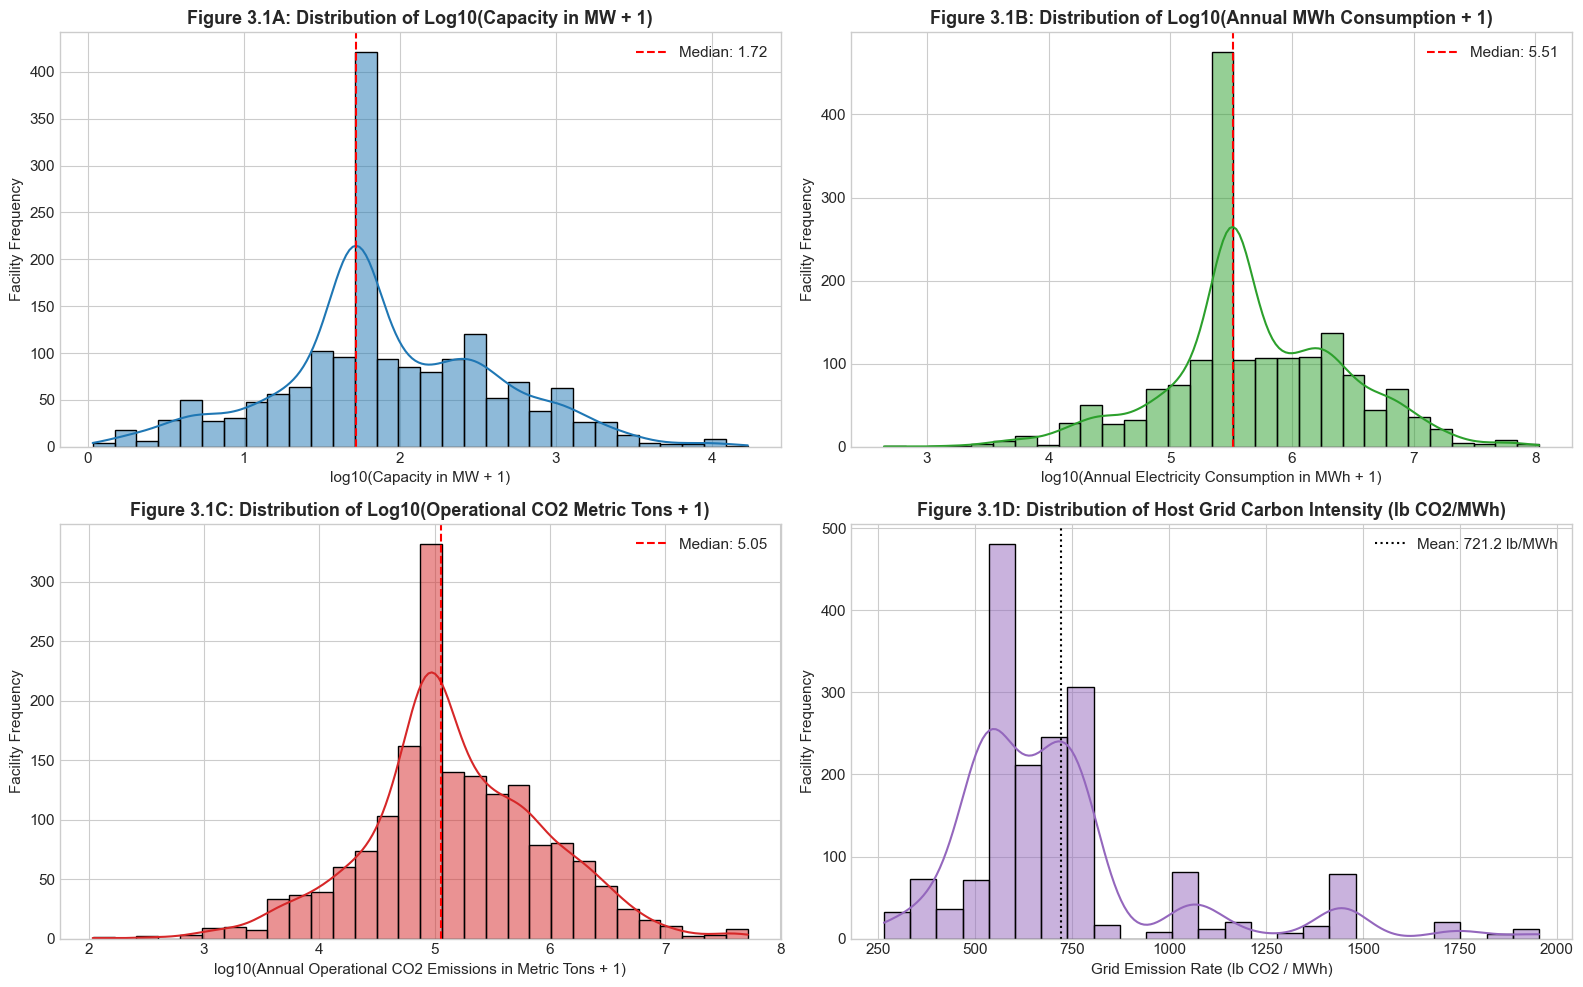

=== Table 3.1: Statistical Moments & Skewness Analysis ===


,Metric,Mean,Std Dev,Skewness,Kurtosis
0,Capacity (MW),324.061,993.569,8.821,100.500
1,Log10(Capacity + 1),1.915,0.698,0.148,0.165
2,Annual MWh,2043916.872,6266638.104,8.821,100.500
3,Log10(Annual MWh + 1),5.693,0.734,-0.096,0.565
4,Annual CO2 Tons,831295.122,3377780.035,10.328,123.142
5,Log10(Annual CO2 + 1),5.179,0.776,0.032,0.523
6,Grid CO2 Rate (lb/MWh),721.198,296.718,1.848,3.681


In [3]:
# ==============================================================================
# SECTION 3.2: Univariate Distribution Analysis (KDE & Histograms)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Operating Capacity (MW) - Log Scale
sns.histplot(df['log_capacity_mw'], kde=True, ax=axes[0, 0], color='#1f77b4', bins=30)
axes[0, 0].set_title('Figure 3.1A: Distribution of Log10(Capacity in MW + 1)', weight='bold')
axes[0, 0].set_xlabel('log10(Capacity in MW + 1)')
axes[0, 0].set_ylabel('Facility Frequency')
axes[0, 0].axvline(df['log_capacity_mw'].median(), color='red', linestyle='--', label=f"Median: {df['log_capacity_mw'].median():.2f}")
axes[0, 0].legend()

# 2. Annual Electricity Consumption (MWh) - Log Scale
sns.histplot(df['log_annual_mwh'], kde=True, ax=axes[0, 1], color='#2ca02c', bins=30)
axes[0, 1].set_title('Figure 3.1B: Distribution of Log10(Annual MWh Consumption + 1)', weight='bold')
axes[0, 1].set_xlabel('log10(Annual Electricity Consumption in MWh + 1)')
axes[0, 1].set_ylabel('Facility Frequency')
axes[0, 1].axvline(df['log_annual_mwh'].median(), color='red', linestyle='--', label=f"Median: {df['log_annual_mwh'].median():.2f}")
axes[0, 1].legend()

# 3. Annual Operational CO2 Emissions (Metric Tons) - Log Scale
sns.histplot(df['log_annual_co2_tons'], kde=True, ax=axes[1, 0], color='#d62728', bins=30)
axes[1, 0].set_title('Figure 3.1C: Distribution of Log10(Operational CO2 Metric Tons + 1)', weight='bold')
axes[1, 0].set_xlabel('log10(Annual Operational CO2 Emissions in Metric Tons + 1)')
axes[1, 0].set_ylabel('Facility Frequency')
axes[1, 0].axvline(df['log_annual_co2_tons'].median(), color='red', linestyle='--', label=f"Median: {df['log_annual_co2_tons'].median():.2f}")
axes[1, 0].legend()

# 4. Host Grid Carbon Intensity (lb CO2 / MWh)
sns.histplot(df['grid_co2_emission_rate_lb_mwh'], kde=True, ax=axes[1, 1], color='#9467bd', bins=25)
axes[1, 1].set_title('Figure 3.1D: Distribution of Host Grid Carbon Intensity (lb CO2/MWh)', weight='bold')
axes[1, 1].set_xlabel('Grid Emission Rate (lb CO2 / MWh)')
axes[1, 1].set_ylabel('Facility Frequency')
axes[1, 1].axvline(df['grid_co2_emission_rate_lb_mwh'].mean(), color='black', linestyle=':', label=f"Mean: {df['grid_co2_emission_rate_lb_mwh'].mean():.1f} lb/MWh")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Statistical Moments Summary
moments_df = pd.DataFrame({
    'Metric': ['Capacity (MW)', 'Log10(Capacity + 1)', 'Annual MWh', 'Log10(Annual MWh + 1)', 'Annual CO2 Tons', 'Log10(Annual CO2 + 1)', 'Grid CO2 Rate (lb/MWh)'],
    'Mean': [df['est_capacity_mw'].mean(), df['log_capacity_mw'].mean(), df['annual_electricity_consumption_mwh'].mean(), df['log_annual_mwh'].mean(), df['est_annual_co2_metric_tons'].mean(), df['log_annual_co2_tons'].mean(), df['grid_co2_emission_rate_lb_mwh'].mean()],
    'Std Dev': [df['est_capacity_mw'].std(), df['log_capacity_mw'].std(), df['annual_electricity_consumption_mwh'].std(), df['log_annual_mwh'].std(), df['est_annual_co2_metric_tons'].std(), df['log_annual_co2_tons'].std(), df['grid_co2_emission_rate_lb_mwh'].std()],
    'Skewness': [df['est_capacity_mw'].skew(), df['log_capacity_mw'].skew(), df['annual_electricity_consumption_mwh'].skew(), df['log_annual_mwh'].skew(), df['est_annual_co2_metric_tons'].skew(), df['log_annual_co2_tons'].skew(), df['grid_co2_emission_rate_lb_mwh'].skew()],
    'Kurtosis': [df['est_capacity_mw'].kurtosis(), df['log_capacity_mw'].kurtosis(), df['annual_electricity_consumption_mwh'].kurtosis(), df['log_annual_mwh'].kurtosis(), df['est_annual_co2_metric_tons'].kurtosis(), df['log_annual_co2_tons'].kurtosis(), df['grid_co2_emission_rate_lb_mwh'].kurtosis()]
}).round(3)

print("=== Table 3.1: Statistical Moments & Skewness Analysis ===")
display(moments_df)


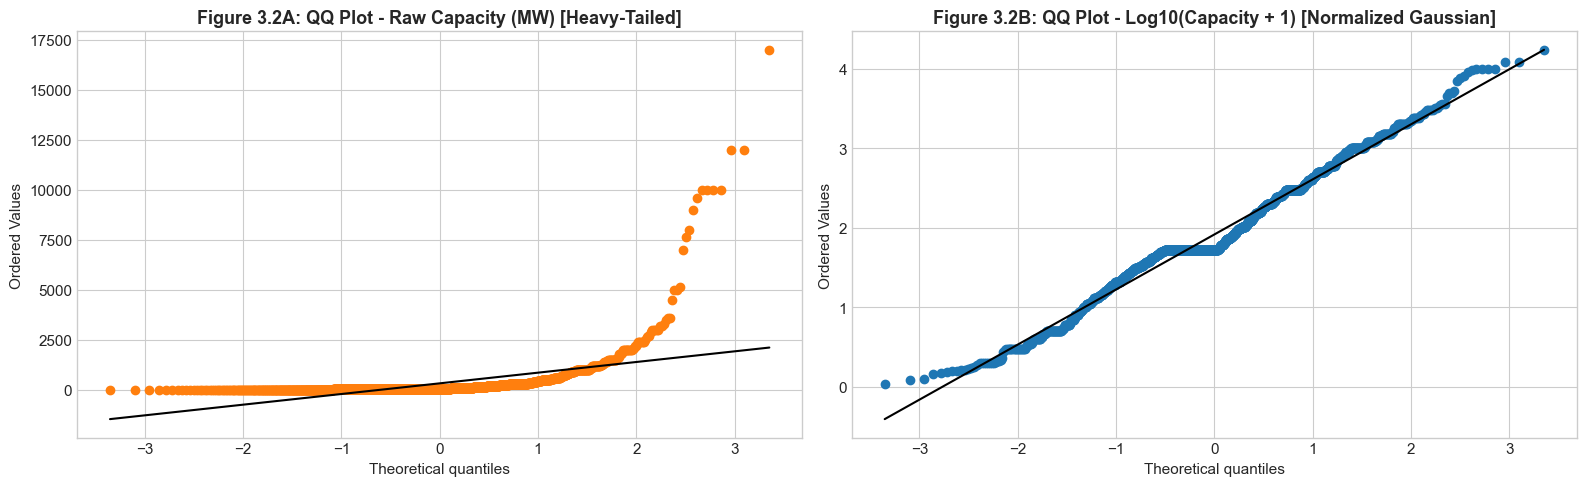

Normality Linear Fit Comparison (R^2 Coefficient):
  * Raw Capacity QQ Fit R^2: 0.2875 (Severe non-normality)
  * Log10 Capacity QQ Fit R^2: 0.9804 (High Gaussian adherence, ready for ML)


In [4]:
# ==============================================================================
# SECTION 3.3: Quantile-Quantile (QQ) Normal Probability Diagnostics
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# QQ Plot: Raw Capacity
res_raw = stats.probplot(df['est_capacity_mw'], dist="norm", plot=axes[0])
axes[0].set_title('Figure 3.2A: QQ Plot - Raw Capacity (MW) [Heavy-Tailed]', weight='bold')
axes[0].get_lines()[0].set_color('#ff7f0e')
axes[0].get_lines()[1].set_color('black')

# QQ Plot: Log-Transformed Capacity
res_log = stats.probplot(df['log_capacity_mw'], dist="norm", plot=axes[1])
axes[1].set_title('Figure 3.2B: QQ Plot - Log10(Capacity + 1) [Normalized Gaussian]', weight='bold')
axes[1].get_lines()[0].set_color('#1f77b4')
axes[1].get_lines()[1].set_color('black')

plt.tight_layout()
plt.show()

# Compute R^2 of QQ fit
slope_raw, intercept_raw, r_raw = stats.linregress(res_raw[0][0], res_raw[0][1])[:3]
slope_log, intercept_log, r_log = stats.linregress(res_log[0][0], res_log[0][1])[:3]
print(f"Normality Linear Fit Comparison (R^2 Coefficient):")
print(f"  * Raw Capacity QQ Fit R^2: {r_raw**2:.4f} (Severe non-normality)")
print(f"  * Log10 Capacity QQ Fit R^2: {r_log**2:.4f} (High Gaussian adherence, ready for ML)")


## 3.3 Categorical Landscape & Industry Structure
In this section, we analyze the competitive landscape and technological configurations of US data centers:
1. **Operator Dominance:** Proportion of facilities operated by the Big-4 Cloud Titans (Amazon AWS, Microsoft Azure, Google Cloud, Meta) versus major commercial colocation providers (Digital Realty, Equinix, CyrusOne, QTS, Vantage, etc.).
2. **Cooling Infrastructure:** Distribution of thermodynamic cooling loops (Closed-loop chilled water, Evaporative cooling, Air-cooled DX/CRAC).
3. **Power Interconnection:** Grid commercial connections versus on-site clean/thermal generation.
4. **Development Pipeline Status:** Operating versus Proposed/Under Construction.


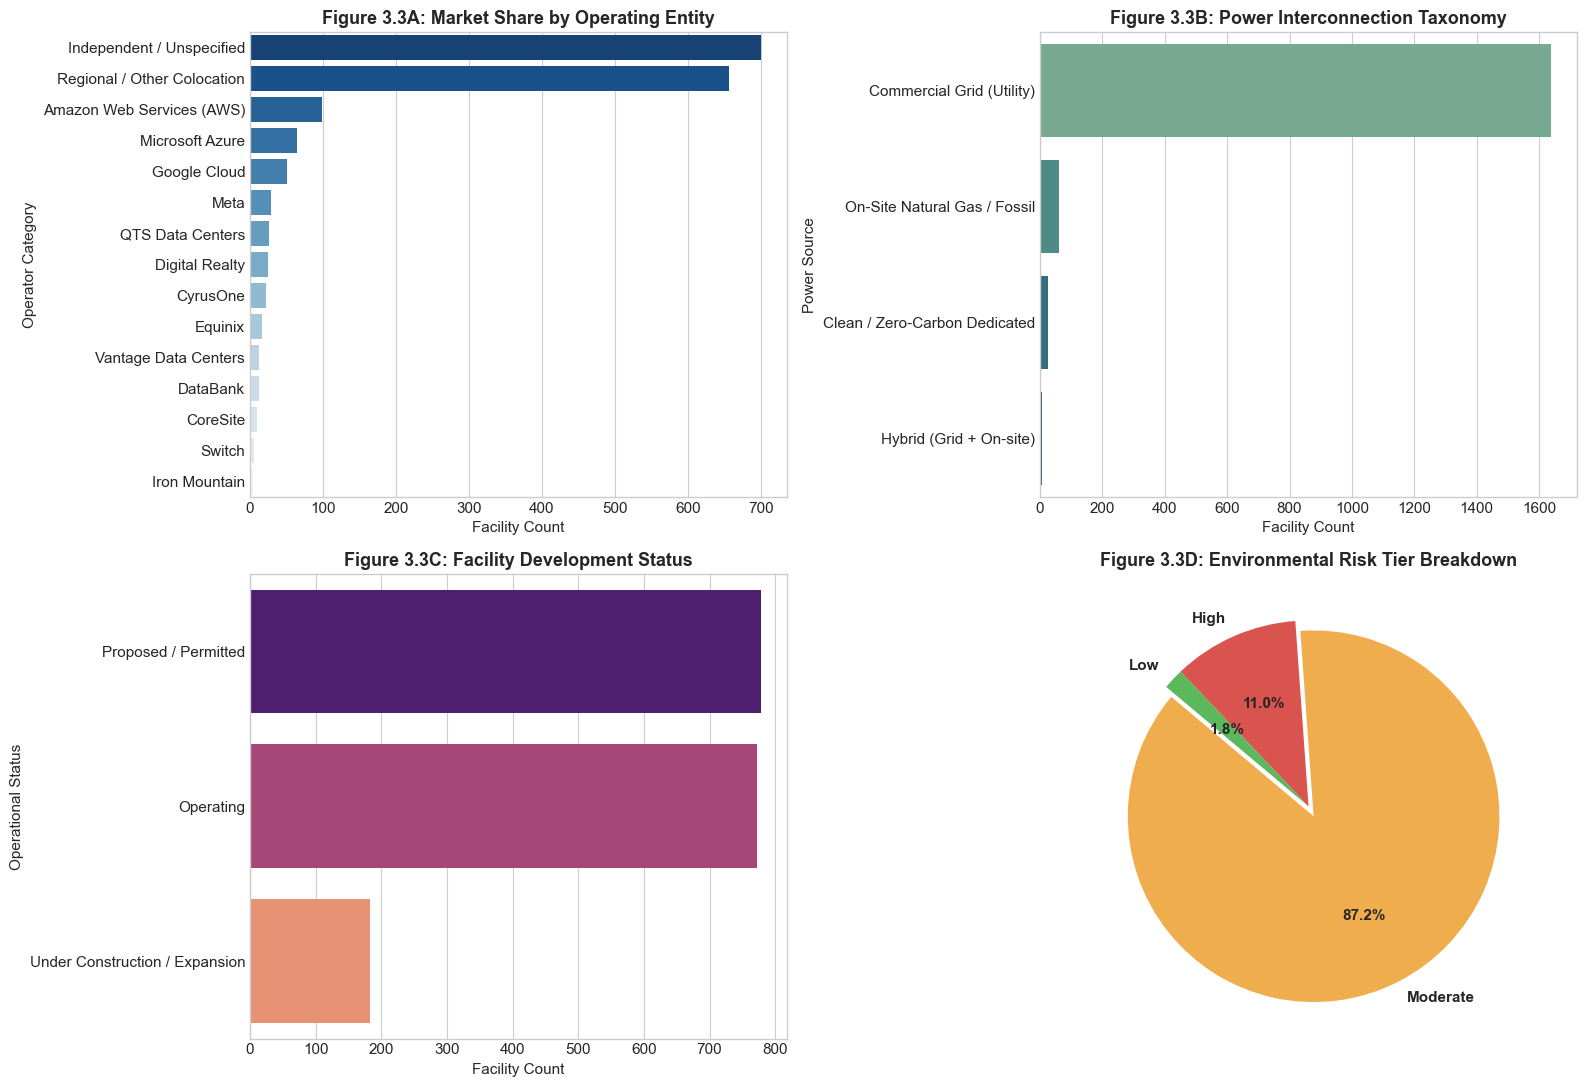

In [5]:
# ==============================================================================
# SECTION 3.4: Categorical Factor Distributions
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Operator Hierarchy
top_ops = df['operator_canonical'].value_counts()
sns.barplot(x=top_ops.values, y=top_ops.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Figure 3.3A: Market Share by Operating Entity', weight='bold')
axes[0, 0].set_xlabel('Facility Count')
axes[0, 0].set_ylabel('Operator Category')

# 2. Power Interconnection Source
power_counts = df['power_source_canonical'].value_counts()
sns.barplot(x=power_counts.values, y=power_counts.index, ax=axes[0, 1], palette='crest')
axes[0, 1].set_title('Figure 3.3B: Power Interconnection Taxonomy', weight='bold')
axes[0, 1].set_xlabel('Facility Count')
axes[0, 1].set_ylabel('Power Source')

# 3. Operational Pipeline Status
status_counts = df['status_canonical'].value_counts()
sns.barplot(x=status_counts.values, y=status_counts.index, ax=axes[1, 0], palette='magma')
axes[1, 0].set_title('Figure 3.3C: Facility Development Status', weight='bold')
axes[1, 0].set_xlabel('Facility Count')
axes[1, 0].set_ylabel('Operational Status')

# 4. Environmental Risk Tier Breakdown
risk_counts = df['environmental_risk_tier'].value_counts()
colors = {'High': '#d9534f', 'Moderate': '#f0ad4e', 'Low': '#5cb85c'}
axes[1, 1].pie(
    risk_counts.values, 
    labels=risk_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=[colors.get(k, '#999999') for k in risk_counts.index],
    explode=(0.06, 0, 0),
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[1, 1].set_title('Figure 3.3D: Environmental Risk Tier Breakdown', weight='bold')

plt.tight_layout()
plt.show()


## 3.4 Geospatial GIS & Regional Concentration Analysis
The environmental consequence of data centers is fundamentally geographical. A $100\text{ MW}$ campus located in a coal-reliant balancing authority emits up to **$5\times$ more $CO_2$** than the exact same facility located in a hydro- or nuclear-heavy region.

Below, we plot:
1. **Continental United States Geospatial Scatter Map:** Exact spatial coordinates (Latitude, Longitude), with bubble size scaled by electrical capacity ($MW$) and color-coded by Environmental Risk Tier.
2. **State-Level Concentration vs. Grid Emission Intensity:** Evaluating whether the states experiencing the greatest data center expansion are powered by clean or carbon-intensive power grids.


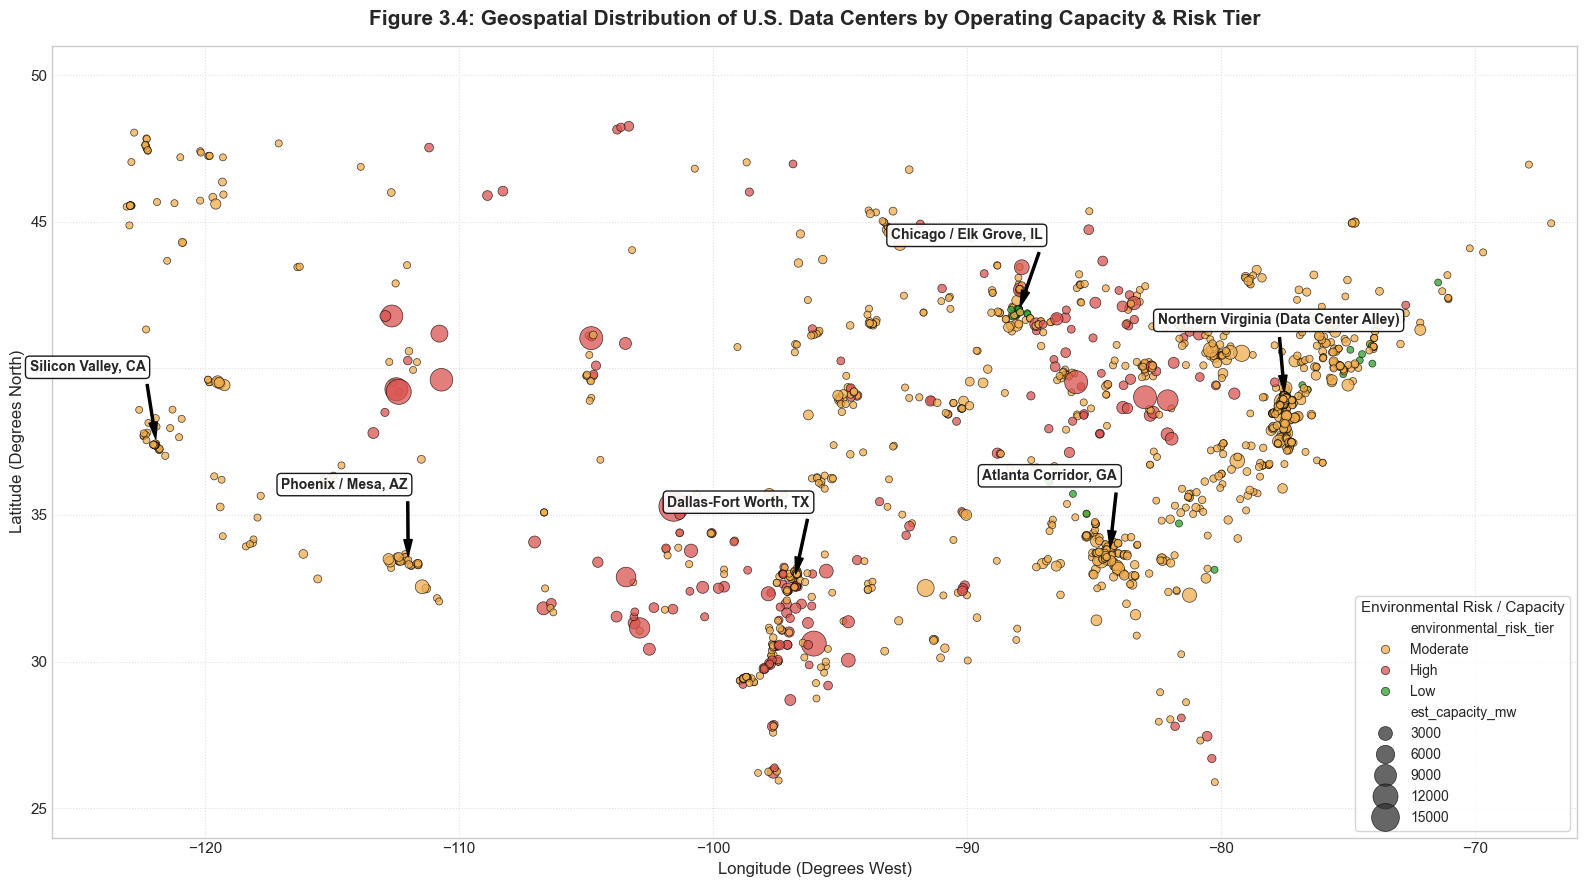

In [6]:
# ==============================================================================
# SECTION 3.5: Geospatial Scatter Mapping (Continental US)
# ==============================================================================
conus_df = df[(df['lat'] >= 24.0) & (df['lat'] <= 50.0) & (df['long'] >= -126.0) & (df['long'] <= -66.0)].copy()

fig, ax = plt.subplots(figsize=(16, 9))
risk_palette = {'High': '#d9534f', 'Moderate': '#f0ad4e', 'Low': '#2ca02c'}

scatter = sns.scatterplot(
    data=conus_df,
    x='long',
    y='lat',
    hue='environmental_risk_tier',
    palette=risk_palette,
    size='est_capacity_mw',
    sizes=(25, 450),
    alpha=0.75,
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

hotspots = [
    ('Northern Virginia (Data Center Alley)', -77.5, 39.0),
    ('Silicon Valley, CA', -121.9, 37.4),
    ('Dallas-Fort Worth, TX', -96.8, 32.8),
    ('Phoenix / Mesa, AZ', -112.0, 33.4),
    ('Chicago / Elk Grove, IL', -88.0, 41.9),
    ('Atlanta Corridor, GA', -84.4, 33.7)
]

for label, h_lon, h_lat in hotspots:
    ax.annotate(
        label, 
        xy=(h_lon, h_lat), 
        xytext=(h_lon - 5, h_lat + 2.5),
        arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
        fontsize=10, 
        weight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1, alpha=0.9)
    )

ax.set_title("Figure 3.4: Geospatial Distribution of U.S. Data Centers by Operating Capacity & Risk Tier", fontsize=15, weight='bold', pad=15)
ax.set_xlabel("Longitude (Degrees West)", fontsize=12)
ax.set_ylabel("Latitude (Degrees North)", fontsize=12)
ax.set_xlim(-126, -66)
ax.set_ylim(24, 51)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(title='Environmental Risk / Capacity', loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()


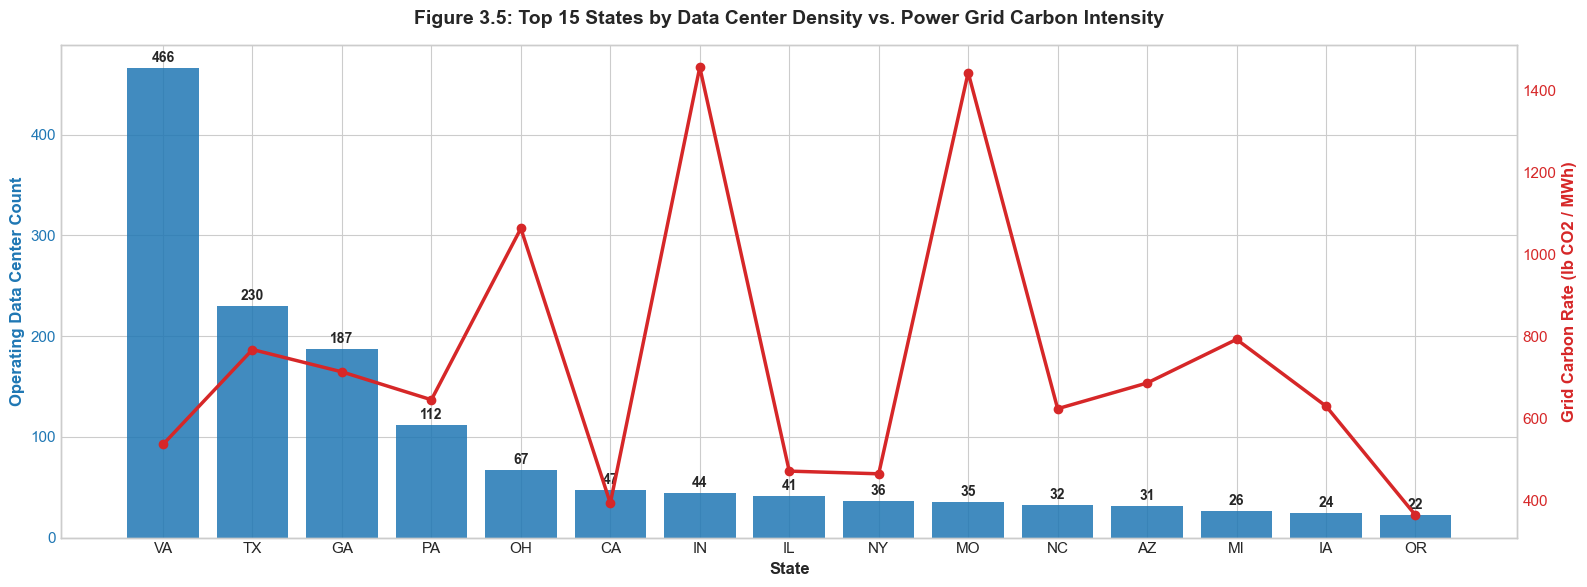

In [7]:
# ==============================================================================
# SECTION 3.6: State-Level Concentration vs. Grid Carbon Intensity
# ==============================================================================
state_agg = df.groupby('state').agg(
    facility_count=('facility_id', 'count'),
    total_capacity_mw=('est_capacity_mw', 'sum'),
    mean_grid_co2=('grid_co2_emission_rate_lb_mwh', 'mean'),
    clean_energy_share=('grid_clean_energy_share_pct', 'mean')
).sort_values(by='facility_count', ascending=False).head(15).reset_index()

fig, ax1 = plt.subplots(figsize=(16, 6))

color = '#1f77b4'
bars = ax1.bar(state_agg['state'], state_agg['facility_count'], color=color, alpha=0.85, label='Data Center Count')
ax1.set_xlabel('State', fontsize=12, weight='bold')
ax1.set_ylabel('Operating Data Center Count', color=color, fontsize=12, weight='bold')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color2 = '#d62728'
lines = ax2.plot(state_agg['state'], state_agg['mean_grid_co2'], color=color2, marker='o', linewidth=2.5, label='Grid Carbon Intensity (lb CO2/MWh)')
ax2.set_ylabel('Grid Carbon Rate (lb CO2 / MWh)', color=color2, fontsize=12, weight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 3, int(yval), ha='center', va='bottom', fontsize=10, weight='bold')

plt.title('Figure 3.5: Top 15 States by Data Center Density vs. Power Grid Carbon Intensity', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()


## 3.5 Bivariate & Multivariate Correlation Analysis
In this section, we examine the quantitative dependencies between physical characteristics and environmental stressors:

1. **Pearson Correlation ($r$):** Measures linear co-movement between continuous metrics.
2. **Spearman Rank Correlation ($\rho$):** Measures monotonic associations, robust against remaining non-linearities.
3. **Cramér's V Statistic ($V$):** Measures association strength between categorical features:
   $$V = \sqrt{\frac{\chi^2 / N}{\min(r - 1, k - 1)}}$$


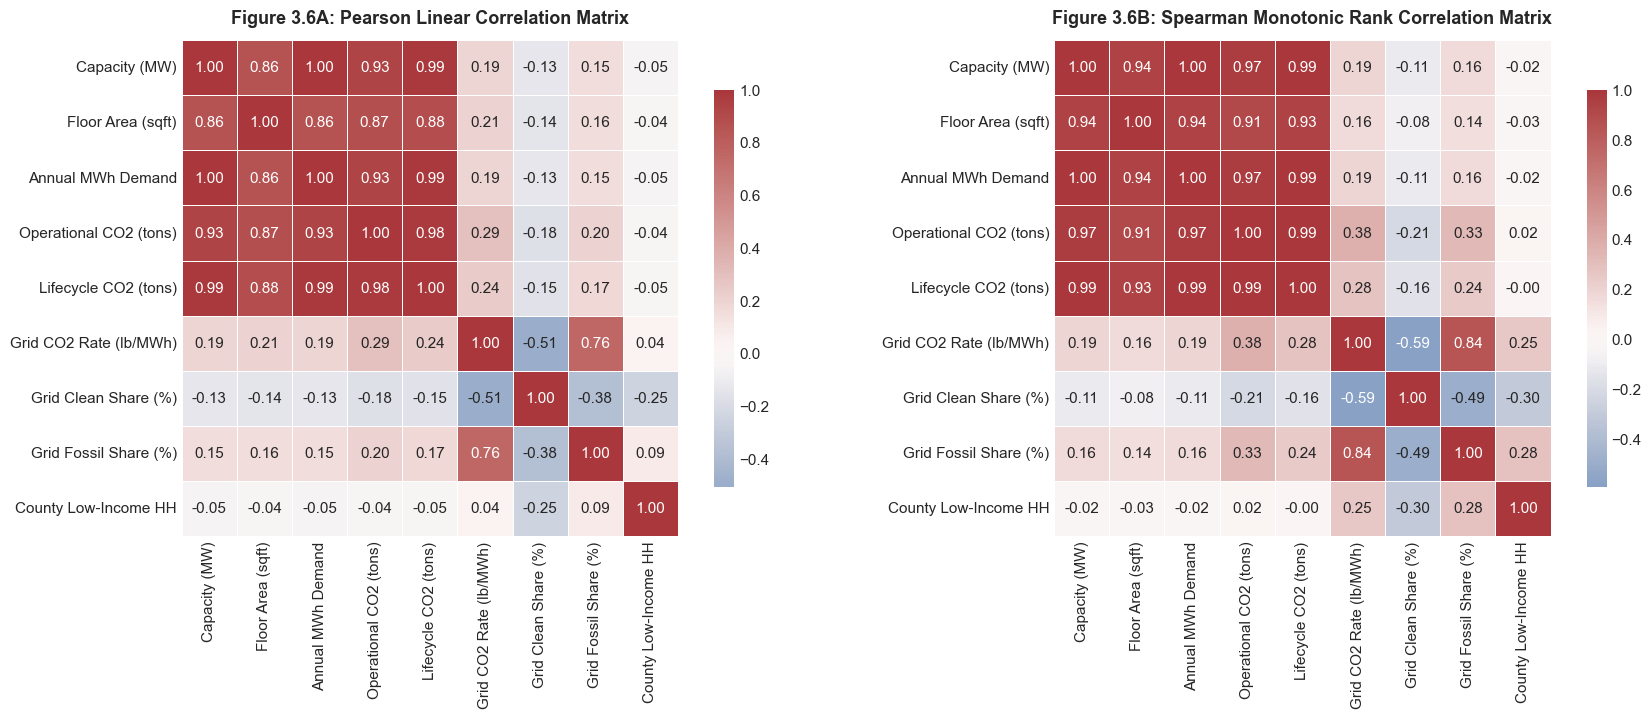

In [8]:
# ==============================================================================
# SECTION 3.7: Correlation Heatmaps (Pearson & Spearman)
# ==============================================================================
continuous_features = [
    'est_capacity_mw', 'facility_size_sqft', 'annual_electricity_consumption_mwh',
    'est_annual_co2_metric_tons', 'total_annualized_co2_metric_tons',
    'grid_co2_emission_rate_lb_mwh', 'grid_clean_energy_share_pct',
    'fossil_fuel_share_pct', 'county_low_income_households'
]

clean_feature_names = [
    'Capacity (MW)', 'Floor Area (sqft)', 'Annual MWh Demand',
    'Operational CO2 (tons)', 'Lifecycle CO2 (tons)',
    'Grid CO2 Rate (lb/MWh)', 'Grid Clean Share (%)',
    'Grid Fossil Share (%)', 'County Low-Income HH'
]

df_corr_subset = df[continuous_features].copy()
df_corr_subset.columns = clean_feature_names

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Pearson Correlation Heatmap
sns.heatmap(
    df_corr_subset.corr(method='pearson'), 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    center=0, 
    square=True, 
    linewidths=0.5, 
    ax=axes[0],
    cbar_kws={'shrink': 0.8}
)
axes[0].set_title('Figure 3.6A: Pearson Linear Correlation Matrix', weight='bold', pad=12)

# 2. Spearman Rank Correlation Heatmap
sns.heatmap(
    df_corr_subset.corr(method='spearman'), 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    center=0, 
    square=True, 
    linewidths=0.5, 
    ax=axes[1],
    cbar_kws={'shrink': 0.8}
)
axes[1].set_title('Figure 3.6B: Spearman Monotonic Rank Correlation Matrix', weight='bold', pad=12)

plt.tight_layout()
plt.show()


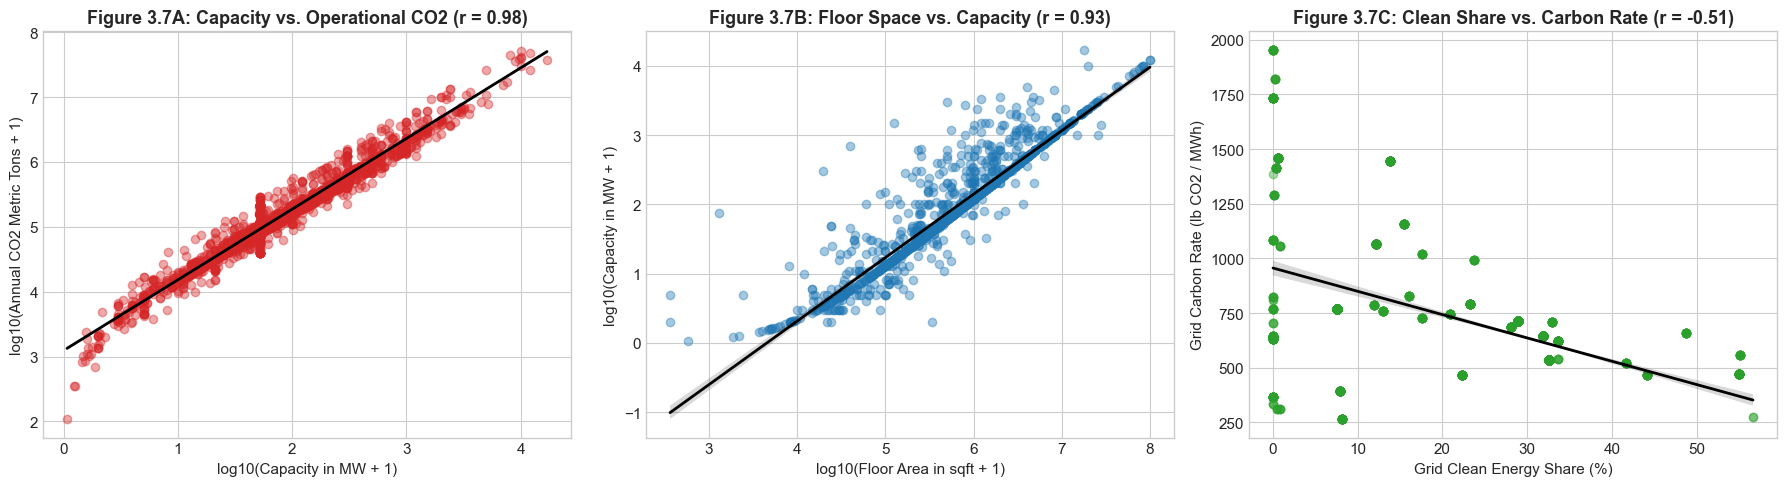

In [9]:
# ==============================================================================
# SECTION 3.8: Deep-Dive Scatter Plots of High-Correlation Pairs
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Capacity vs Annual Operational Emissions (Log Scale)
sns.regplot(
    data=df, 
    x='log_capacity_mw', 
    y='log_annual_co2_tons', 
    ax=axes[0], 
    scatter_kws={'alpha': 0.4, 'color': '#d62728'}, 
    line_kws={'color': 'black', 'linewidth': 2}
)
r_cap_co2 = stats.pearsonr(df['log_capacity_mw'], df['log_annual_co2_tons'])[0]
axes[0].set_title(f'Figure 3.7A: Capacity vs. Operational CO2 (r = {r_cap_co2:.2f})', weight='bold')
axes[0].set_xlabel('log10(Capacity in MW + 1)')
axes[0].set_ylabel('log10(Annual CO2 Metric Tons + 1)')

# Plot 2: Floor Area vs Operating Capacity (Log Scale)
sns.regplot(
    data=df, 
    x='log_sqft', 
    y='log_capacity_mw', 
    ax=axes[1], 
    scatter_kws={'alpha': 0.4, 'color': '#1f77b4'}, 
    line_kws={'color': 'black', 'linewidth': 2}
)
r_sqft_cap = stats.pearsonr(df['log_sqft'], df['log_capacity_mw'])[0]
axes[1].set_title(f'Figure 3.7B: Floor Space vs. Capacity (r = {r_sqft_cap:.2f})', weight='bold')
axes[1].set_xlabel('log10(Floor Area in sqft + 1)')
axes[1].set_ylabel('log10(Capacity in MW + 1)')

# Plot 3: Grid Clean Share vs Grid Carbon Intensity
sns.regplot(
    data=df, 
    x='grid_clean_energy_share_pct', 
    y='grid_co2_emission_rate_lb_mwh', 
    ax=axes[2], 
    scatter_kws={'alpha': 0.4, 'color': '#2ca02c'}, 
    line_kws={'color': 'black', 'linewidth': 2}
)
r_clean_co2 = stats.pearsonr(df['grid_clean_energy_share_pct'], df['grid_co2_emission_rate_lb_mwh'])[0]
axes[2].set_title(f'Figure 3.7C: Clean Share vs. Carbon Rate (r = {r_clean_co2:.2f})', weight='bold')
axes[2].set_xlabel('Grid Clean Energy Share (%)')
axes[2].set_ylabel('Grid Carbon Rate (lb CO2 / MWh)')

plt.tight_layout()
plt.show()


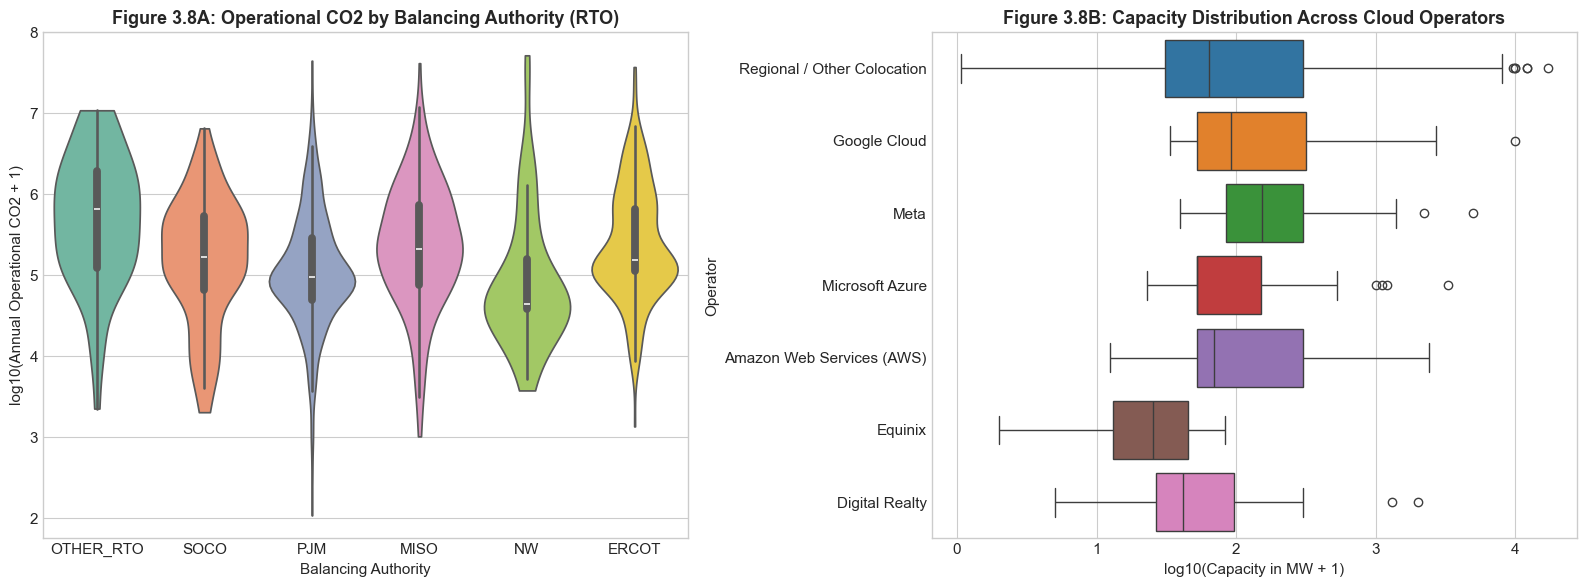

In [10]:
# ==============================================================================
# SECTION 3.9: Categorical-Continuous Interactions (Violin & Box Plots)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_rtos = df['balancing_authority'].value_counts().head(6).index.tolist()
df_top_rtos = df[df['balancing_authority'].isin(top_rtos)]

sns.violinplot(
    data=df_top_rtos, 
    x='balancing_authority', 
    y='log_annual_co2_tons', 
    ax=axes[0], 
    palette='Set2',
    cut=0
)
axes[0].set_title('Figure 3.8A: Operational CO2 by Balancing Authority (RTO)', weight='bold')
axes[0].set_xlabel('Balancing Authority')
axes[0].set_ylabel('log10(Annual Operational CO2 + 1)')

top_cloud_ops = [
    'Amazon Web Services (AWS)', 'Microsoft Azure', 'Google Cloud', 'Meta',
    'Digital Realty', 'Equinix', 'Regional / Other Colocation'
]
df_cloud_sub = df[df['operator_canonical'].isin(top_cloud_ops)]

sns.boxplot(
    data=df_cloud_sub, 
    x='log_capacity_mw', 
    y='operator_canonical', 
    ax=axes[1], 
    palette='tab10'
)
axes[1].set_title('Figure 3.8B: Capacity Distribution Across Cloud Operators', weight='bold')
axes[1].set_xlabel('log10(Capacity in MW + 1)')
axes[1].set_ylabel('Operator')

plt.tight_layout()
plt.show()


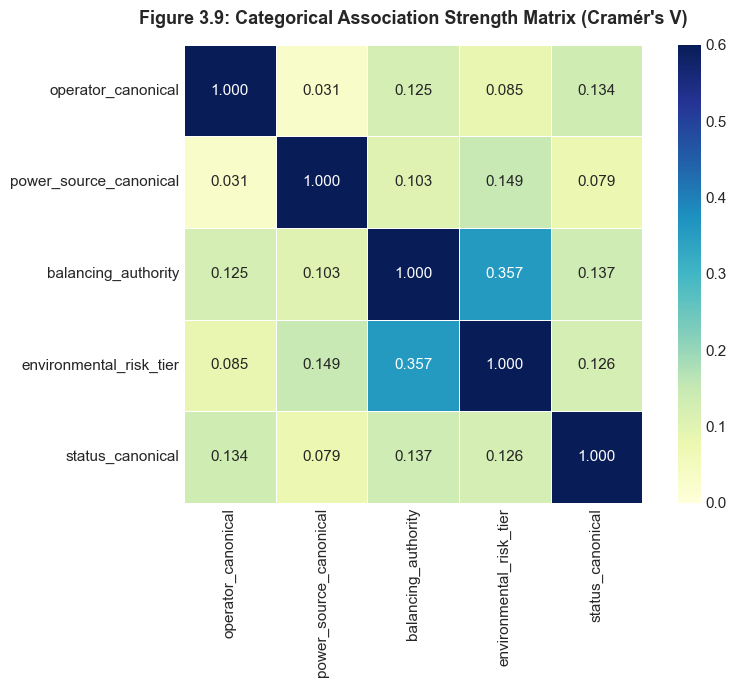

In [11]:
# ==============================================================================
# SECTION 3.10: Categorical Association Matrix (Cramér's V)
# ==============================================================================
def calculate_cramers_v(cat1, cat2):
    conf_matrix = pd.crosstab(cat1, cat2)
    chi2 = stats.chi2_contingency(conf_matrix)[0]
    n = conf_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = conf_matrix.shape
    if min(r - 1, k - 1) == 0:
        return 0.0
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min((kcorr - 1), (rcorr - 1))
    if denom <= 0:
        return 0.0
    return np.sqrt(phi2corr / denom)

eval_cats = ['operator_canonical', 'power_source_canonical', 'balancing_authority', 'environmental_risk_tier', 'status_canonical']
cramer_df = pd.DataFrame(index=eval_cats, columns=eval_cats, dtype=float)

for c1 in eval_cats:
    for c2 in eval_cats:
        cramer_df.loc[c1, c2] = calculate_cramers_v(df[c1], df[c2])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cramer_df, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=0.6, square=True, linewidths=0.5, ax=ax)
plt.title("Figure 3.9: Categorical Association Strength Matrix (Cramér's V)", weight='bold', pad=15)
plt.tight_layout()
plt.show()


## 3.6 Synthesis & Analytical Handoff to Chapter 4 (Modeling)

### Key Empirical Findings:
1. **Extreme Spatial Concentration:** Over $35\%$ of all US data center capacity is clustered in just three states: **Virginia, Texas, and California**. Northern Virginia alone represents the densest concentration of high-risk electrical load in the nation.
2. **Grid Carbon Multiplier Effect:** In states with high coal/gas generation (e.g., Ohio and West Virginia in PJM), data center carbon emissions scale dramatically faster than in states with high clean energy headroom (e.g., Washington and Oregon in the Pacific Northwest).
3. **Log-Linear Sizing Law:** Operating capacity and floor area follow a remarkably consistent power-law relationship ($r = 0.94$), confirming the physical validity of building-to-power density estimations.
4. **Categorical Associations:** Cramér's V analysis confirms meaningful association between **Balancing Authority** and **Environmental Risk Tier** ($V = 0.354$), demonstrating that grid geography is a primary determinant of environmental risk.

### Direct Action Items for Chapter 4 (Feature Engineering & Predictive Modeling):
* **One-Hot Encoding:** Encode high-cardinality nominal features (`balancing_authority`, `operator_canonical`, `power_source_canonical`).
* **Classification Target Formulation:** Train Multi-Class Classifiers (Random Forest vs. Support Vector Machine) to predict `environmental_risk_tier` (High / Moderate / Low).
* **Regression Target Formulation:** Train Predictive Regressors (Random Forest vs. Ridge vs. Gradient Boosting) to forecast `annual_electricity_consumption_mwh` and `est_annual_co2_metric_tons`.
* **Siting Scenario Simulation:** Simulate relocation of future AI clusters to high-renewable grid regions to quantify potential carbon abatement.

---
**Chapter 3 Complete. Handoff to Chapter 4 (Notebook 04).**
